# Plot Venn Diagrams between 2 experiments

Experiments
* Handpicked 37 jets (Guo et al. 2022)
* Fontanka (Galitsyna et al., 2023) 
* Fun (Liu et al., 2024) 
* MIA-Jet 

In [1]:
import sys
sys.path.append('..')
from utils.plotting import plot_n_hic, genomic_labels
from notebooks.func_iou import *
from notebooks.func_pileup import *

import os
import pandas as pd
import itertools
from matplotlib_venn import venn2
import matplotlib.pyplot as plt
import bioframe as bf
import numpy as np
import yaml

In [2]:
def safe_int(x):
    try:
        return int(x)
    except ValueError:
        return x

# Across all experiments

Processing experiment: Repli-HiC_K562_WT_totalS_50kb
* Selected MIA-Jet summary table: Repli-HiC_K562_WT_totalS_chr_combined_q_val_0.5_50Kb_summary_table.csv
Common chromosomes: ['chr1', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr20', 'chr21', 'chr22', 'chrX', 'chrY', 'chrM']


Retrieving pileups: 100%|██████████| 791/791 [00:12<00:00, 65.63it/s] 


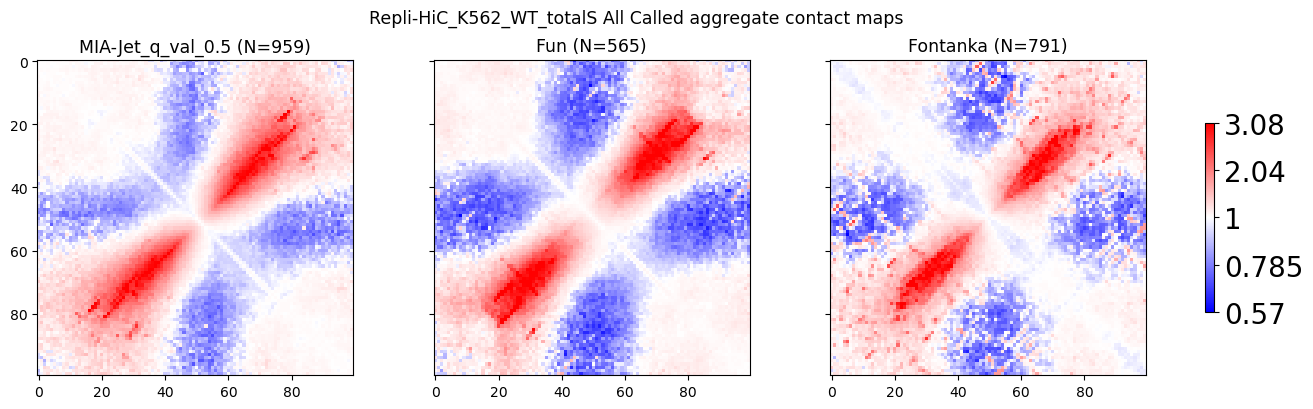

--------------------
Comparing MIA-Jet_q_val_0.5 and Fun...
--------------------
Comparing MIA-Jet_q_val_0.5 and Fontanka...
--------------------
Comparing Fun and Fontanka...
Genome-wide overlaps:
                   MIA-Jet_q_val_0.5    Fun  Fontanka
MIA-Jet_q_val_0.5              959.0  378.0     410.0
Fun                            378.0  565.0     244.0
Fontanka                       410.0  244.0     791.0


Retrieving pileups: 100%|██████████| 547/547 [00:05<00:00, 93.17it/s] 


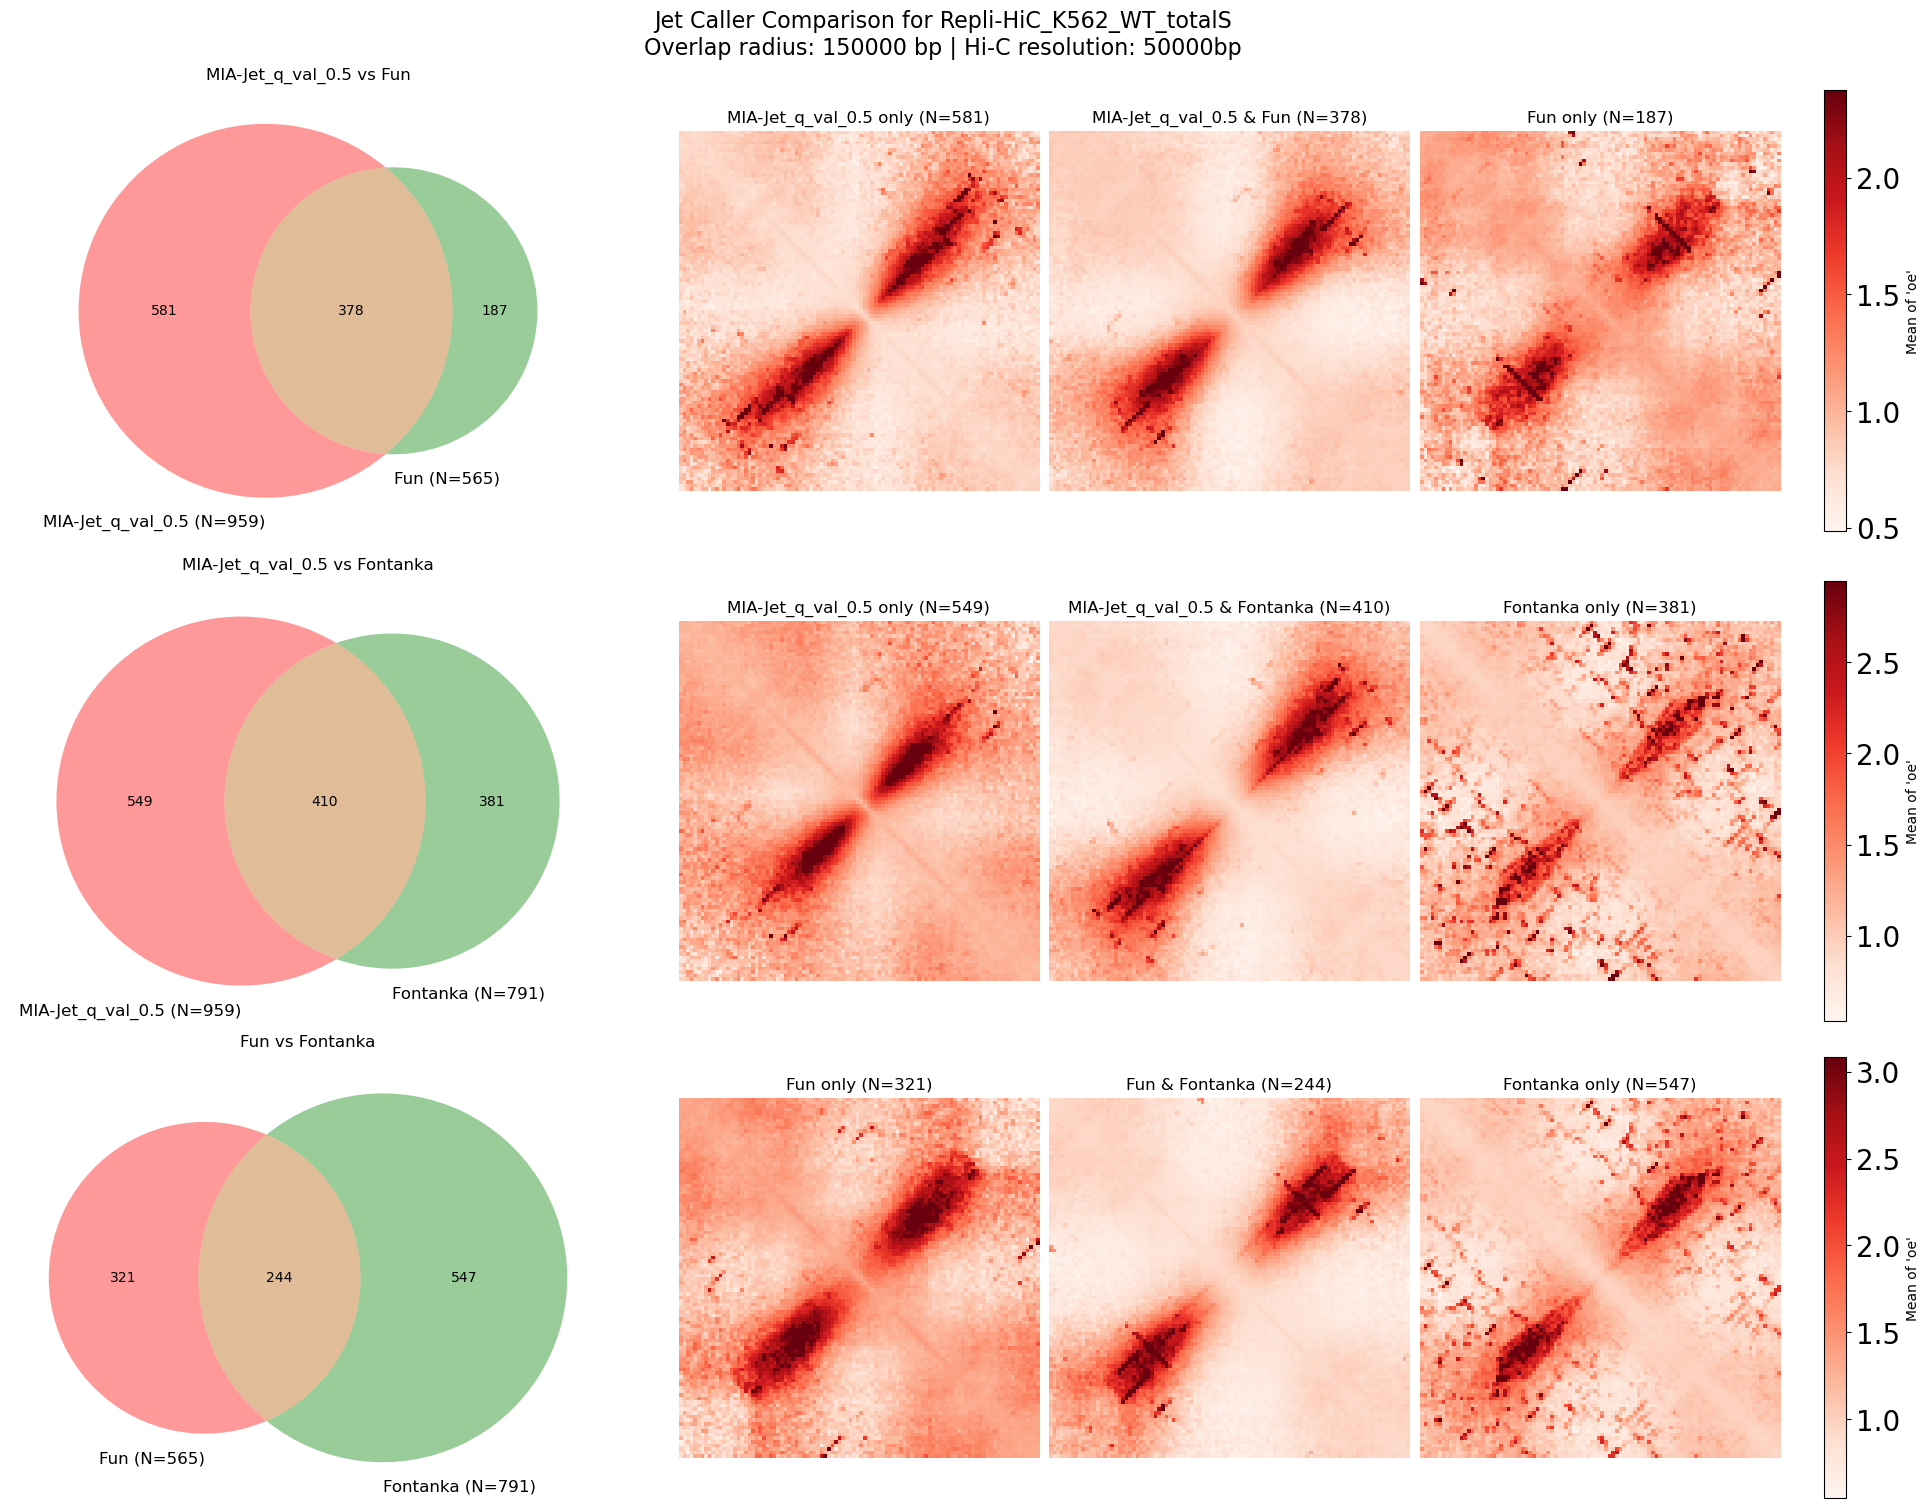

In [4]:
# Load config
config_yaml = """
Repli-HiC_K562_WT_totalS_50kb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/Repli-HiC_K562_WT_totalS.hic"
    genome: "hg19"
    norm: "VC_SQRT"
    res: "50000"
    exp: "replihic"
    mcool: "/nfs/turbo/umms-minjilab/downloaded_data/Repli-HiC_K562_WT_totalS.ice.mcool"
    win: "6000000"
    chroms: "all"
    q_val: "0.5"
    extra_args:
    - "--diagnostic_plots"
"""
samples = yaml.safe_load(config_yaml)

# Analysis parameters
output_name = "v2.0.3"
save_path = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/revision2"

os.makedirs(save_path, exist_ok=True)

# Pileup parameters
data_type = "oe"
expected_stack_size = 100

# Overlap parameters
iou_threshold = 0  # ANY overlap

for key, attributes in samples.items():
    print(f"Processing experiment: {key}")

    hic_file = attributes["file"]

    if "q_val" in attributes.keys():
        q_val_str = f"q_val_{attributes['q_val']}"
    else:
        q_val_str = "q_val_0.1" # default

    if "q_val_white" in attributes.keys():
        q_val_white_str = f"{q_val_str}-{attributes['q_val_white']}"
    elif attributes['exp'] == "replihic" or "compartment" in attributes.keys() and attributes['compartment'] == "False":
        q_val_white_str = f"{q_val_str}" # no white q-value
    else:
        q_val_white_str = f"{q_val_str}-0.95" # default


    basename_hic = os.path.basename(hic_file)
    data_name_hic = os.path.splitext(basename_hic)[0]

    data_name = data_name_hic

    resolution = int(attributes["res"])
    normalization = attributes["norm"]
    genome = attributes["genome"]

    # Standardize normalization to "VC_SQRT" due to hicstraw reading in issues
    # However, if "NONE" then keep it as is
    print("\tWarning: standardizing normalization to 'VC_SQRT' (if not 'NONE') for hicstraw compatibility")
    if normalization == "VC":
        pass # Then continue because these are the downsampled files
    elif normalization != "NONE":
        normalization = "VC_SQRT"

    # Overlap parameter is relative to resolution
    buffer_radius = 3 * resolution  # 5 bins

    # FUN
    f_pred_fun_bedpe = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_{data_name_hic}_{resolution // 1e3:.0f}kb/FUN-pred_{resolution}_1.3.bedpe"
    f_pred_fun_tab = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_{data_name_hic}_{resolution // 1e3:.0f}kb/FUN-pred_{resolution}_1.3.tab"


    # FONTANKA
    # Only 50 kb exists for now with ws-small
    if data_name == "Repli-HiC_K562_WT_totalS":
        # If Repli Hi-C, don't apply the stringent filters
        f_pred_fontanka = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FONTANKA_ws-small_{data_name_hic}_{resolution // 1e3:.0f}kb.{resolution}.predicted.fountains.thresholded-weak.tsv"
    else:
        f_pred_fontanka = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FONTANKA_ws-small_{data_name_hic}_{resolution // 1e3:.0f}kb.{resolution}.predicted.fountains.thresholded.tsv"


    # MIA-JET
    # The result_type will change across different files
    hic_name = os.path.basename(hic_file).split(".hic")[0]
    folder = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{hic_name}_chr_combined_{genomic_labels(resolution)}"
    prefix = f"{hic_name}_chr_combined_"
    suffix = f"_{genomic_labels(resolution)}_summary_table.csv"
    fname = next(f for f in os.listdir(folder) if f.startswith(prefix) and f.endswith(suffix) and q_val_white_str in f)
    print(f"* Selected MIA-Jet summary table: {fname}")
    result_type = fname[len(prefix):-len(suffix)]
    f_pred_miajet_summary = os.path.join(folder, fname)
    f_pred_miajet_expanded = os.path.join(folder, f"{hic_name}_chr_combined_{result_type}_{genomic_labels(resolution)}_expanded_table.csv")

    # Load it in
    if os.path.exists(f_pred_fun_bedpe) and os.path.exists(f_pred_fun_tab):
        fun_bedpe = pd.read_csv(f_pred_fun_bedpe, sep="\t")
        fun_table = pd.read_csv(f_pred_fun_tab, sep="\t")
    else:
        fun_bedpe = None
        fun_table = None


    if os.path.exists(f_pred_fontanka):
        fontanka_table = pd.read_csv(f_pred_fontanka, sep="\t", index_col=0)
        fontanka_table.dropna(inplace=True, how="any")
        fontanka_table.reset_index(inplace=True, drop=True)
    else:
        fontanka_table = None

    miajet_positions = pd.read_csv(f_pred_miajet_expanded, comment="#")
    miajet_table = pd.read_csv(f_pred_miajet_summary, comment="#")

    chrom_sizes = bf.fetch_chromsizes(genome, as_bed=True)
    common_chroms = chrom_sizes["chrom"].tolist()

    miajet_table = miajet_table[miajet_table["chrom"].isin(common_chroms)]

    if fun_table is not None:
        fun_table = fun_table[fun_table["chrom"].isin(common_chroms)]
    if fontanka_table is not None:
        fontanka_table = fontanka_table[fontanka_table["chrom"].isin(common_chroms)]

    print(f"Common chromosomes: {common_chroms}")

    if fun_bedpe is not None:
        # Process FUN
        fun_bedpe["extrusion_x"] = (fun_bedpe["y1"] + fun_bedpe["y2"]) / 2
        fun_bedpe["extrusion_y"] = (fun_bedpe["x1"] + fun_bedpe["x2"]) / 2
        assert np.all(fun_bedpe["extrusion_x"] >= fun_bedpe["extrusion_y"])


        fun_table["root"] = (fun_table["start"] + fun_table["end"]) / 2
        fun_table["unique_id"] = fun_table.index

        fun_minimal = fun_bedpe.copy()
        fun_minimal["root"] = fun_table["root"]

        fun_minimal["unique_id"] = fun_minimal.index
        fun_minimal["chrom"] = fun_table["chrom"]

        fun_minimal = fun_minimal[["unique_id", "chrom", "root", "extrusion_x", "extrusion_y"]]

        fun_positions = generate_positions(fun_minimal, resolution)
        fun_positions["unique_id"] = fun_positions["unique_id"].astype(int)
    else:
        fun_positions = None

    if fontanka_table is not None:
        # Process Fontanka
        fontanka_table = fontanka_table.reset_index(drop=True)
        fontanka_table["root"] = (fontanka_table["end"] + fontanka_table["start"]) / 2
        fontanka_table["unique_id"] = fontanka_table.index
        fontanka_table["extrusion_x"] = fontanka_table["window_end"]
        fontanka_table["extrusion_y"] = fontanka_table["window_start"]
        assert np.all(fontanka_table["extrusion_x"] >= fontanka_table["extrusion_y"])

        fontanka_minimal = fontanka_table.copy()
        fontanka_minimal = fontanka_minimal[["unique_id", "chrom", "root", "extrusion_x", "extrusion_y"]]

        fontanka_positions = generate_positions(fontanka_minimal, resolution)
        fontanka_positions["unique_id"] = fontanka_positions["unique_id"].astype(int)
    else:
        fontanka_positions = None

    # Combine
    positions = [miajet_positions]
    tables = [miajet_table]
    names = [f"MIA-Jet_{result_type}"]

    if fun_positions is not None:
        positions.append(fun_positions)
        tables.append(fun_table)
        names.append("Fun")
    if fontanka_positions is not None:
        positions.append(fontanka_positions)
        tables.append(fontanka_table)
        names.append("Fontanka")


    position_dict = dict(zip(names, positions))
    table_dict = dict(zip(names, tables))

    bed_tables = []
    for i, (s, e) in enumerate(zip(tables, positions)):
        bed_tables.append(generate_bed_2(s, e, eps=500e3, fraction=1.5))

    if data_type == "observed":
        cmap = "Reds"
        vcenter = None
    else:
        cmap = "bwr"
        vcenter = 1


    # PLOT ALL CALLED
    agg_map = []
    vmaxes = []
    df_stack = []
    for bed_df in bed_tables:
        # Get pileups for each bed_df
        s, d, r = get_pileups_dynamic_resolution(
            hic_file=hic_file,
            bed_df_in=bed_df,
            expected_stack_size=expected_stack_size,
            chrom_sizes=chrom_sizes,
            chromosomes='all',
            window_range=(None, None),
            data_type=data_type,
            normalization=normalization,
            sort=True,
            verbose=True
        )

        # Remove centromeres and resize square stacks
        s, d = remove_and_resize_square_stacks(s, d, expected_stack_size)

        if data_type == "observed":
            s = np.log10(s + 1) # log transform for visualization

        a = np.mean(s, axis=0)
        vm = np.percentile(a, 99) if np.percentile(a, 99) > np.nanmin(a) else np.nanmax(a)
        vmaxes.append(vm)  # store the 99th percentile for color scaling
        agg_map.append(a)  # average over all stacks
        df_stack.append(d)  # store the DataFrame for later use

    titles = [f"{names[i]} (N={len(df_stack[i])})" for i in range(len(names))]


    plot_n_hic(
        agg_map,
        suptitle=f"{data_name} All Called aggregate contact maps",
        resolution=None,
        cmap_label=None,
        titles=titles,
        cmap=cmap,
        vcenter=vcenter,
        standardize_cbar=True,
        show=True,
        vmax=vmaxes,
        ppr=4,
        # savepath=f"{save_path}/{data_name}_{resolution}_MIA-Jet_{result_type}_all_agg_map-{data_type}.png",
        cbar_fontsize=20,
    )


    # COMPUTE OVERLAPS
    results = pd.DataFrame(index=names, columns=names, dtype=int).fillna(0)
    unique_identifiers = []
    name_pairs = []
    # fill main diagonal with the total number of jets from each method
    for n in names:
        results.loc[n, n] = len(table_dict[n])

    for n1, n2 in itertools.combinations(names, 2):

        print("-" * 20)
        print(f"Comparing {n1} and {n2}...")

        genome_wide_overlap = 0
        identifiers = []

        for chrom in common_chroms:
            # IOU method is per-chromosome so filter each table by chromosome
            t1 = position_dict[n1].loc[position_dict[n1]["chrom"] == chrom]
            t2 = position_dict[n2].loc[position_dict[n2]["chrom"] == chrom]

            # Compute the pairs of jets in each direction
            pairs12 = match_by_iou(t1, t2, buffer_radius=buffer_radius, iou_threshold=iou_threshold, x_label="x (bp)", y_label="y (bp)")
            pairs21 = match_by_iou(t2, t1, buffer_radius=buffer_radius, iou_threshold=iou_threshold, x_label="x (bp)", y_label="y (bp)")

            # Construct graph and find unique pairs
            pairs = unique_pairs(pairs12, pairs21, method="optimal")

            genome_wide_overlap += len(pairs)
            identifiers += pairs # extend the list

        # Update reuslts table
        results.loc[n1, n2] = genome_wide_overlap
        results.loc[n2, n1] = genome_wide_overlap  # symmetric

        unique_identifiers.append(identifiers)
        name_pairs.append((n1, n2))

    print("Genome-wide overlaps:")
    print(results)


    # COLLECT AGG DATA
    agg_map_pairs = [] # aggregate contact map data
    for (n1, n2), pairs in zip(name_pairs, unique_identifiers):
        safe_convert = np.vectorize(safe_int)

        if len(pairs) == 0:
            uid1 = np.array([])
            uid2 = np.array([])
        else:
            uid1 = np.array(pairs)[:, 0]  # unique identifiers from n1
            uid2 = np.array(pairs)[:, 1]  # unique identifiers from n2

            uid1 = safe_convert(uid1)
            uid2 = safe_convert(uid2)

        df1 = pd.DataFrame({"unique_id" : uid1,})
        df2 = pd.DataFrame({"unique_id" : uid2,})
        # Summary dataframe
        df_A = table_dict[n1]
        df_B = table_dict[n2]
        # These will be used to merge to extract the relevant positions
        df_id = df1
        df_id_alt = df2
        # Expanded dataframe
        df_pos_A = position_dict[n1].copy()
        df_pos_B = position_dict[n2].copy()

        # These are the "main" summary dataframes
        # That should be sufficien to plot the aggregate contact maps and boxplots
        df_intersection = df_A[df_A["unique_id"].isin(df_id["unique_id"])].reset_index(drop=True)
        df_diff_A = df_A[~df_A["unique_id"].isin(df_id["unique_id"])].reset_index(drop=True)
        df_diff_B = df_B[~df_B["unique_id"].isin(df_id_alt["unique_id"])].reset_index(drop=True)

        # Assertions to ensure that the intersection and difference cover the whole table
        assert len(df_intersection) + len(df_diff_A) == len(df_A), "The intersection and difference should cover the whole table"
        assert len(df_intersection) + len(df_diff_B) == len(df_B), "The intersection and difference should cover the whole table"

        # AGGREGATE CONTACT MAPS
        df_pos_intersection = df_pos_A[df_pos_A["unique_id"].isin(df_id["unique_id"])].reset_index(drop=True)
        df_pos_diff_A = df_pos_A[~df_pos_A["unique_id"].isin(df_id["unique_id"])].reset_index(drop=True)
        df_pos_diff_B = df_pos_B[~df_pos_B["unique_id"].isin(df_id_alt["unique_id"])].reset_index(drop=True)

        # Make bed files to get stacks
        bed_intersection = generate_bed_2(df_intersection, df_pos_intersection, eps=500e3, fraction=1.5)
        bed_diff_A = generate_bed_2(df_diff_A, df_pos_diff_A, eps=500e3, fraction=1.5)
        bed_diff_B = generate_bed_2(df_diff_B, df_pos_diff_B, eps=500e3, fraction=1.5)

        bed_frames = [bed_diff_A, bed_intersection, bed_diff_B]

        agg_map = []
        for bed_df in bed_frames:
            # Get pileups for each bed_df
            s, d, r = get_pileups_dynamic_resolution(
                hic_file=hic_file,
                bed_df_in=bed_df,
                expected_stack_size=expected_stack_size,
                chrom_sizes=chrom_sizes,
                chromosomes='all',
                window_range=(None, None),
                data_type=data_type,
                normalization=normalization,
                sort=True,
                verbose=True
            )

            # Remove centromeres and resize square stacks
            s, d = remove_and_resize_square_stacks(s, d, expected_stack_size)

            if data_type == "observed":
                s = np.log10(s + 1) # log transform for visualization

            agg_map.append(np.mean(s, axis=0))  # average over all stacks

        agg_map_pairs.append(agg_map)

    agg_map_pairs = np.array(agg_map_pairs)

    # PLOT VENN DIAGRAM
    if len(names) > 1:
        pairs = list(itertools.combinations(names, 2))
        num_pairs = len(pairs)

        fig, axes = plt.subplots(num_pairs, 4, figsize=(5*4, 5*num_pairs), layout='constrained', width_ratios=[2, 1, 1, 1], squeeze=False)

        for row, (A, B) in enumerate(pairs):
            # compute overlaps as before
            total_A = results.loc[A, A]
            total_B = results.loc[B, B]
            inter   = results.loc[A, B]
            only_A  = total_A - inter
            only_B  = total_B - inter

            # column 0: the Venn
            ax = axes[row, 0]
            venn2(subsets=(int(only_A), int(only_B), int(inter)),
                set_labels=(f"{A} (N={int(total_A)})", f"{B} (N={int(total_B)})"),
                ax=ax)
            ax.set_title(f"{A} vs {B}")

            # columns 1–3: the three imshows
            # agg_map_pairs.shape == (n_pairs, 3, H, W)
            titles = [f"{A} only", f"{A} & {B}", f"{B} only"]
            counts = [int(only_A), int(inter), int(only_B)]
            row_imgs = agg_map_pairs[row]
            row_vmax = max(np.percentile(img, 99) for img in row_imgs)
            for col_idx in range(3):
                ax = axes[row, col_idx+1]
                img = agg_map_pairs[row, col_idx]
                im = ax.imshow(img, cmap="Reds", interpolation="none", vmax=np.percentile(img, 99))
                ax.set_title(f"{titles[col_idx]} (N={counts[col_idx]})")
                ax.axis('off')
            cba = fig.colorbar(im, ax=axes[row, 1:], fraction=0.02, pad=0.04, label=f"Mean of '{data_type}'")

            cba.ax.tick_params(labelsize=20)


        fig.suptitle(f"Jet Caller Comparison for {data_name}\nOverlap radius: {int(buffer_radius)} bp | Hi-C resolution: {resolution}bp", fontsize=16)

        # plt.savefig(f"{save_path}/{data_name}_{resolution}_MIA-Jet_{result_type}_venn_diagram-agg.png", dpi=300)

        plt.show()